In [1]:
from pathlib import Path
import sys

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline

raiz = Path.cwd().resolve()
if not (raiz / "dados").is_dir():
    raiz = raiz.parent
if not (raiz / "dados").is_dir():
    raise FileNotFoundError("Execute o notebook a partir da raiz do projeto ou da pasta script.")
sys.path.insert(0, str(raiz / "src"))

from preprocessamento import (carregar_dados, preparar_dados, criar_preprocessador,
                              criar_particoes, NUMERICAS, CATEGORICAS)
from avaliacao import avaliar_modelo

saida = raiz / "resultados"
saida.mkdir(exist_ok=True)
caminho = raiz / "dados" / "online_shoppers_convertido.csv"
dados = carregar_dados(caminho)
print("Dimensões da base convertida:", dados.shape)
print("Duplicatas exatas:", dados.duplicated().sum())
print("Valores ausentes:", dados.isna().sum().sum())
display(dados.head())


Dimensões da base convertida: (12330, 18)
Duplicatas exatas: 125
Valores ausentes: 0


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,2,1,1,1,1,1,0,0
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,2,2,2,1,2,1,0,0
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,2,4,1,9,3,1,0,0
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,2,3,2,2,4,1,0,0
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,2,3,3,1,4,1,1,0


In [2]:
X, y = preparar_dados(dados)
particoes = criar_particoes(X, y)
print("Registros após remover duplicatas:", len(X))
print("Atributos numéricos:", NUMERICAS)
print("Atributos categóricos:", CATEGORICAS)
print("Distribuição após remoção das duplicatas:")
display(y.value_counts().sort_index().rename(index={0: "Sem compra", 1: "Compra"}).to_frame("quantidade"))
print("Número de partições estratificadas:", len(particoes))


Registros após remover duplicatas: 12205
Atributos numéricos: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']
Atributos categóricos: ['Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend']
Distribuição após remoção das duplicatas:


,quantidade
Revenue,
Sem compra,10297
Compra,1908


Número de partições estratificadas: 5


## KNN: duas configurações

São comparados `k=5` com pesos uniformes e `k=11` com pesos pela distância. Ambos usam as mesmas cinco partições estratificadas, com embaralhamento e semente 42, que também devem ser usadas pelos demais classificadores do grupo. Não há reamostragem. Métricas: acurácia, precisão, revocação e F1 para a classe compra. As tabelas mostram os valores por fold e a média e o desvio padrão entre folds.


In [3]:
configuracoes = {
    "KNN k=5, uniforme": KNeighborsClassifier(n_neighbors=5, weights="uniform"),
    "KNN k=11, distância": KNeighborsClassifier(n_neighbors=11, weights="distance"),
}
resultados = []
matrizes = {}

for nome, classificador in configuracoes.items():
    # O preprocessador fica dentro do pipeline para ser ajustado em cada treino.
    modelo = Pipeline([
        ("preprocessamento", criar_preprocessador()),
        ("modelo", classificador),
    ])
    metricas, matrizes[nome] = avaliar_modelo(modelo, X, y, particoes)
    resultados.append(metricas.reset_index().assign(configuracao=nome))

# Mantém os nomes e a estrutura dos arquivos produzidos anteriormente.
por_fold = pd.concat(resultados, ignore_index=True).rename(columns={
    "Fold": "fold", "Acurácia": "acuracia", "Precisão": "precisao",
    "Recall": "revocacao", "F1-score": "f1",
})
por_fold = por_fold[["configuracao", "fold", "acuracia", "precisao", "revocacao", "f1"]]
resumo = por_fold.groupby("configuracao")[["acuracia", "precisao", "revocacao", "f1"]].agg(["mean", "std"])
print("Métricas por partição:")
display(por_fold.round(4))
print("Média e desvio padrão entre as cinco partições:")
display(resumo.round(4))
por_fold.to_csv(saida / "knn_metricas_por_fold.csv", index=False, encoding="utf-8-sig")
resumo.to_csv(saida / "knn_metricas_resumo.csv", encoding="utf-8-sig")


Métricas por partição:


,configuracao,fold,acuracia,precisao,revocacao,f1
0,"KNN k=5, uniforme",1,0.8660,0.6174,0.3727,0.4648
1,"KNN k=5, uniforme",2,0.8751,0.6667,0.3990,0.4992
2,"KNN k=5, uniforme",3,0.8755,0.6970,0.3613,0.4759
3,"KNN k=5, uniforme",4,0.8685,0.6287,0.3901,0.4814
4,"KNN k=5, uniforme",5,0.8640,0.6179,0.3429,0.4411
5,"KNN k=11, distância",1,0.8742,0.6927,0.3491,0.4642
6,"KNN k=11, distância",2,0.8755,0.7037,0.3491,0.4667
7,"KNN k=11, distância",3,0.8796,0.7558,0.3403,0.4693
8,"KNN k=11, distância",4,0.8787,0.7048,0.3874,0.5000
9,"KNN k=11, distância",5,0.8746,0.7184,0.3272,0.4496


Média e desvio padrão entre as cinco partições:


acuracia         precisao         revocacao          \
                        mean     std     mean     std      mean     std   
configuracao                                                              
KNN k=11, distância   0.8765  0.0025   0.7151  0.0245    0.3506  0.0224   
KNN k=5, uniforme     0.8698  0.0052   0.6455  0.0351    0.3732  0.0224   

                         f1          
                       mean     std  
configuracao                         
KNN k=11, distância  0.4700  0.0184  
KNN k=5, uniforme    0.4725  0.0215

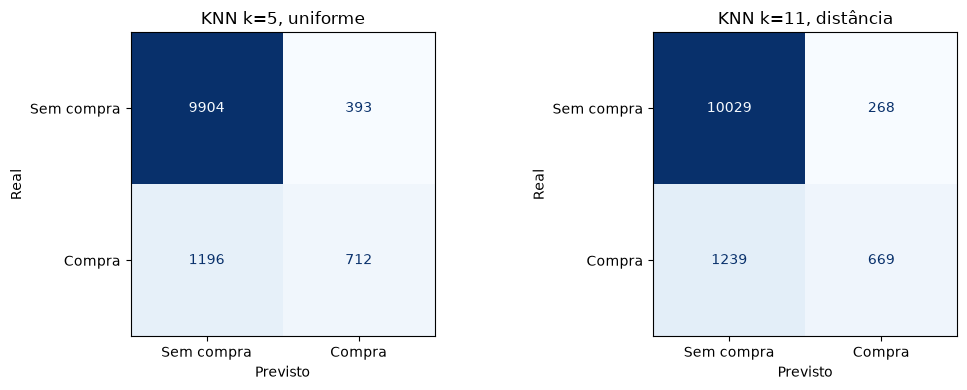

In [4]:
fig, eixos = plt.subplots(1, len(matrizes), figsize=(11, 4))
for eixo, (nome, matriz), arquivo in zip(
    eixos, matrizes.items(), ["matriz_knn_5.csv", "matriz_knn_11.csv"]
):
    ConfusionMatrixDisplay(matriz, display_labels=["Sem compra", "Compra"]).plot(
        ax=eixo, cmap="Blues", colorbar=False, values_format="d"
    )
    eixo.set_title(nome)
    eixo.set_xlabel("Previsto")
    eixo.set_ylabel("Real")
    pd.DataFrame(matriz, index=["real_sem_compra", "real_compra"],
                 columns=["previsto_sem_compra", "previsto_compra"]).to_csv(
                     saida / arquivo, encoding="utf-8-sig")
plt.tight_layout()
plt.savefig(saida / "matrizes_confusao_knn.png", dpi=300)
plt.show()
